<a href="https://colab.research.google.com/github/luisferdm6/02_analisis_hotelero_pandas/blob/main/01_limpieza_y_agrupaciones_hotel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url_dataset = "https://raw.githubusercontent.com/Rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"

df_real = pd.read_csv(url_dataset)

df_real.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [2]:
df_real.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [3]:
df_real.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


In [4]:
df_real ['children'] = df_real ['children'].fillna(0)

df_real ['children'].isnull().sum()

np.int64(0)

In [5]:
df_real = df_real.drop(columns=['company'], errors='ignore')

'company' in df_real.columns

False

In [6]:
df_real ['country'] = df_real ['country'].fillna('Unknown')

df_real ['country'].isnull().sum()

np.int64(0)

In [7]:
df_real ['agent'] = df_real ['agent'].fillna(0)

df_real ['agent'].isnull().sum()

np.int64(0)

In [8]:
df_real ['children'] = df_real ['children'].astype(int)

df_real ['agent'] = df_real ['agent'].astype(int)

df_real [['children', 'agent']].head()

,children,agent
0,0,0
1,0,0
2,0,0
3,0,304
4,0,240


In [9]:
df_real ['is_canceled'].value_counts()

,count
is_canceled,
0,75166
1,44224


In [10]:
df_real ['is_canceled'].value_counts(normalize=True) * 100

,proportion
is_canceled,
0,62.958372
1,37.041628


In [11]:
df_real.groupby('hotel') ['adr'].mean()

,adr
hotel,
City Hotel,105.304465
Resort Hotel,94.952930


In [12]:
df_sin_unknown = df_real[df_real['country'] != 'Unknown']

df_sin_unknown['country'].value_counts(normalize=True).map('{:.2%}'.format).head()

,proportion
country,
PRT,40.87%
GBR,10.20%
FRA,8.76%
ESP,7.21%
DEU,6.13%


In [13]:
df_real.groupby('is_canceled') ['lead_time'].mean()

,lead_time
is_canceled,
0,79.984687
1,144.848815


In [14]:
df_real.groupby('deposit_type') ['is_canceled'].mean() * 100

,is_canceled
deposit_type,
No Deposit,28.377022
Non Refund,99.362446
Refundable,22.222222


In [15]:
df_real['reservation_status_date'] = pd.to_datetime(df_real['reservation_status_date'])

In [16]:
df_real['reservation_status_date'].dtype

dtype('<M8[ns]')

In [17]:
df_real['status_year'] = df_real['reservation_status_date'].dt.year

In [18]:
df_real[['reservation_status_date','status_year']].head()

,reservation_status_date,status_year
0,2015-07-01,2015
1,2015-07-01,2015
2,2015-07-02,2015
3,2015-07-02,2015
4,2015-07-03,2015


In [19]:
df_real['status_day_name'] = df_real['reservation_status_date'].dt.day_name()

df_real['status_day_name'].value_counts(normalize=True).map('{:.2%}'.format)

,proportion
status_day_name,
Monday,15.66%
Friday,15.47%
Thursday,15.19%
Wednesday,15.03%
Tuesday,14.01%
Sunday,13.81%
Saturday,10.83%


In [20]:
# Are Mondays showing higher records due to scheduled check-outs or higher cancellation rates?

df_real.groupby('status_day_name')['is_canceled'].mean().map('{:.2%}'.format)

,is_canceled
status_day_name,
Friday,40.50%
Monday,43.18%
Saturday,23.68%
Sunday,16.13%
Thursday,38.91%
Tuesday,46.37%
Wednesday,45.34%


In [21]:
# What is the Average Daily Rate (ADR) by property type?

df_real.groupby('hotel')['adr'].mean().map('${:.2f}'.format)

,adr
hotel,
City Hotel,$105.30
Resort Hotel,$94.95


In [22]:
# What is the Average Daily Rate (ADR) segmented by hotel type and cancellation status?

df_real['is_canceled'] = df_real['is_canceled'].map({0: 'No', 1: 'Yes'})

df_real.groupby(['hotel','is_canceled'])['adr'].mean().map('${:.2f}'.format).reset_index()

,hotel,is_canceled,adr
0,City Hotel,No,$105.75
1,City Hotel,Yes,$104.69
2,Resort Hotel,No,$90.79
3,Resort Hotel,Yes,$105.79


In [23]:
df_ordenado = df_real.groupby('market_segment')['adr'].mean().reset_index().sort_values(by='adr', ascending=False)

df_ordenado['adr'] = df_ordenado['adr'].map('${:.2f}'.format)

df_ordenado

,market_segment,adr
6,Online TA,$117.20
3,Direct,$115.45
0,Aviation,$100.14
5,Offline TA/TO,$87.35
4,Groups,$79.48
2,Corporate,$69.36
7,Undefined,$15.00
1,Complementary,$2.89


In [24]:
# What is the actual ADR range (min, mean, max) across commercial distribution channels?

resumen_tarifas = df_real.groupby('market_segment')['adr'].agg(['min','mean','max']).reset_index()

resumen_tarifas = resumen_tarifas.sort_values(by='mean',ascending=False)

resumen_tarifas[['min','mean','max']] = resumen_tarifas[['min','mean','max']].map('${:.2f}'.format)

resumen_tarifas

,market_segment,min,mean,max
6,Online TA,$0.00,$117.20,$450.00
3,Direct,$0.00,$115.45,$451.50
0,Aviation,$0.00,$100.14,$193.50
5,Offline TA/TO,$0.00,$87.35,$5400.00
4,Groups,$-6.38,$79.48,$367.00
2,Corporate,$0.00,$69.36,$508.00
7,Undefined,$12.00,$15.00,$18.00
1,Complementary,$0.00,$2.89,$170.00


In [25]:
# Detecting pricing anomalies and extreme outliers

df_real[df_real['adr'] > 5000][['hotel', 'is_canceled', 'reserved_room_type', 'adults', 'children', 'adr']]

,hotel,is_canceled,reserved_room_type,adults,children,adr
48515,City Hotel,Yes,A,2,0,5400.0


In [26]:
df_real[df_real['adr'] < 0][['hotel', 'is_canceled', 'reserved_room_type', 'adults', 'children', 'adr']]

,hotel,is_canceled,reserved_room_type,adults,children,adr
14969,Resort Hotel,No,A,2,0,-6.38


In [27]:
df_real = df_real[(df_real['adr'] >= 0) & (df_real['adr'] < 5000)]

df_real.shape

(119388, 33)

In [28]:
# Verifying anomaly removal across market segments

resumen_limpio = df_real.groupby('market_segment')['adr'].agg(['min','mean','max']).reset_index()

resumen_limpio = resumen_limpio.sort_values(by='mean',ascending=False)

resumen_limpio[['min','mean','max']] = resumen_limpio[['min','mean','max']].map('${:.2f}'.format)

resumen_limpio

,market_segment,min,mean,max
6,Online TA,$0.00,$117.20,$450.00
3,Direct,$0.00,$115.45,$451.50
0,Aviation,$0.00,$100.14,$193.50
5,Offline TA/TO,$0.00,$87.14,$510.00
4,Groups,$0.00,$79.48,$367.00
2,Corporate,$0.00,$69.36,$508.00
7,Undefined,$12.00,$15.00,$18.00
1,Complementary,$0.00,$2.89,$170.00


In [29]:
# What is the Average Length of Stay (ALOS) per property type?

df_real['total_stay'] = df_real['stays_in_week_nights'] + df_real['stays_in_weekend_nights']

df_real.groupby('hotel')['total_stay'].agg(['min','mean','max']).reset_index()

,hotel,min,mean,max
0,City Hotel,0,2.978167,57
1,Resort Hotel,0,4.318405,69


In [30]:
# How much realized room revenue did each property generate from completed stays?

df_real['total_cost'] = df_real['total_stay'] * df_real['adr']

ingresos_hotel = df_real[df_real['is_canceled'] == 'No'].groupby('hotel')['total_cost'].sum().reset_index()

ingresos_hotel['total_cost'] = ingresos_hotel['total_cost'].map('${:,.2f}'.format)

ingresos_hotel

,hotel,total_cost
0,City Hotel,"$14,394,410.18"
1,Resort Hotel,"$11,601,914.03"


In [31]:
# Which property suffers the largest gross revenue loss from cancelled bookings?

ingresos_perdidos = df_real[df_real['is_canceled'] == 'Yes'].groupby('hotel')['total_cost'].sum().reset_index()

ingresos_perdidos['total_cost'] = ingresos_perdidos['total_cost'].map('${:,.2f}'.format)

ingresos_perdidos

,hotel,total_cost
0,City Hotel,"$10,879,659.78"
1,Resort Hotel,"$5,842,177.34"


In [32]:
# What exact percentage of total bookings results in cancellation for each hotel?

df_real['cancelada_num'] = df_real['is_canceled'] == 'Yes'

tasa_cancelacion = df_real.groupby('hotel')['cancelada_num'].mean().map('{:.2%}'.format).reset_index()

tasa_cancelacion

,hotel,cancelada_num
0,City Hotel,41.73%
1,Resort Hotel,27.76%


In [33]:
# Which commercial distribution channels drive the highest cancellation rates?

tasa_segmento = df_real.groupby('market_segment')['cancelada_num'].mean().sort_values(ascending=False).map('{:.2%}'.format).reset_index()

tasa_segmento

,market_segment,cancelada_num
0,Undefined,100.00%
1,Groups,61.07%
2,Online TA,36.72%
3,Offline TA/TO,34.31%
4,Aviation,21.94%
5,Corporate,18.73%
6,Direct,15.34%
7,Complementary,13.06%


In [34]:
# How many bookings did the Undefined channel actually have, and which channel drives the highest volume?

total_reservas = df_real.groupby('market_segment').agg(
    total_reservas = ('is_canceled','count'),
    cancelaciones = ('cancelada_num','sum'),
    tasa_cancelacion = ('cancelada_num','mean')
).reset_index()

total_reservas = total_reservas.sort_values(by='total_reservas',ascending=False)

total_reservas['tasa_cancelacion'] = total_reservas['tasa_cancelacion'].map('{:.2%}'.format)

total_reservas


,market_segment,total_reservas,cancelaciones,tasa_cancelacion
6,Online TA,56477,20739,36.72%
5,Offline TA/TO,24218,8310,34.31%
4,Groups,19810,12097,61.07%
3,Direct,12606,1934,15.34%
2,Corporate,5295,992,18.73%
1,Complementary,743,97,13.06%
0,Aviation,237,52,21.94%
7,Undefined,2,2,100.00%


In [35]:
# How many days in advance (lead time) do confirmed guests book compared to cancelled bookings?

anticipacion_cancelacion = df_real.groupby('is_canceled')['lead_time'].agg(['mean','median']).reset_index()

anticipacion_cancelacion

,is_canceled,mean,median
0,No,79.983157,45.0
1,Yes,144.851299,113.0


In [36]:
# How do cancellation rates behave across different deposit policy types?

resumen_deposito = df_real.groupby('deposit_type').agg(
    total_reservas = ('is_canceled','count'),
    cancelaciones = ('cancelada_num','sum'),
    tasa_cancelacion = ('cancelada_num','mean')
).sort_values(by='total_reservas', ascending=False).reset_index()

resumen_deposito['tasa_cancelacion'] = resumen_deposito['tasa_cancelacion'].map('{:.2%}'.format)

resumen_deposito

,deposit_type,total_reservas,cancelaciones,tasa_cancelacion
0,No Deposit,104640,29694,28.38%
1,Non Refund,14586,14493,99.36%
2,Refundable,162,36,22.22%


In [37]:
# Are repeated guests more reliable than first-time guests in terms of cancellation rate?

resumen_lealtad = df_real.groupby('is_repeated_guest').agg(
    total_reservas = ('is_canceled','count'),
    cancelaciones = ('cancelada_num','sum'),
    tasa_cancelacion = ('cancelada_num','mean')
).reset_index()

resumen_lealtad['is_repeated_guest'] = resumen_lealtad['is_repeated_guest'].map({0 : 'No', 1 : 'Yes'})

resumen_lealtad['tasa_cancelacion'] = resumen_lealtad['tasa_cancelacion'].map('{:.2%}'.format)

resumen_lealtad

,is_repeated_guest,total_reservas,cancelaciones,tasa_cancelacion
0,No,115579,43671,37.78%
1,Yes,3809,552,14.49%


In [38]:
import matplotlib.pyplot as plt

import seaborn as sns


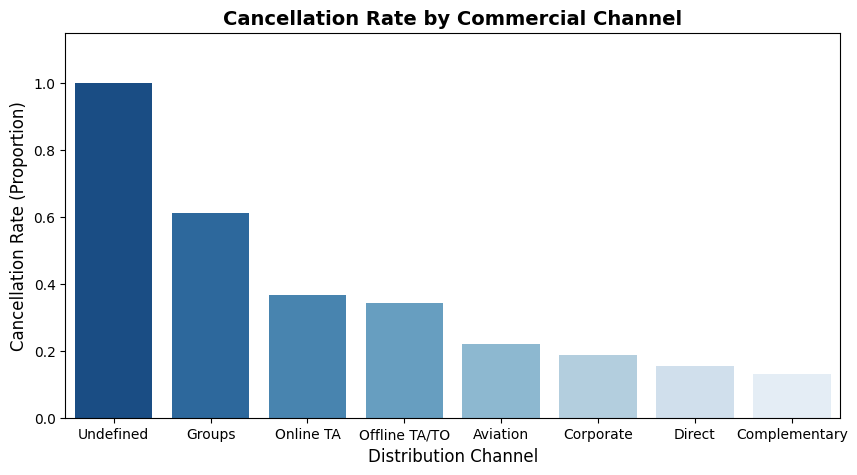

In [39]:
datos_grafica = df_real.groupby('market_segment')['cancelada_num'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=datos_grafica, x='market_segment', y='cancelada_num')
plt.title('Cancellation Rate by Commercial Distribution Channel')
plt.show()

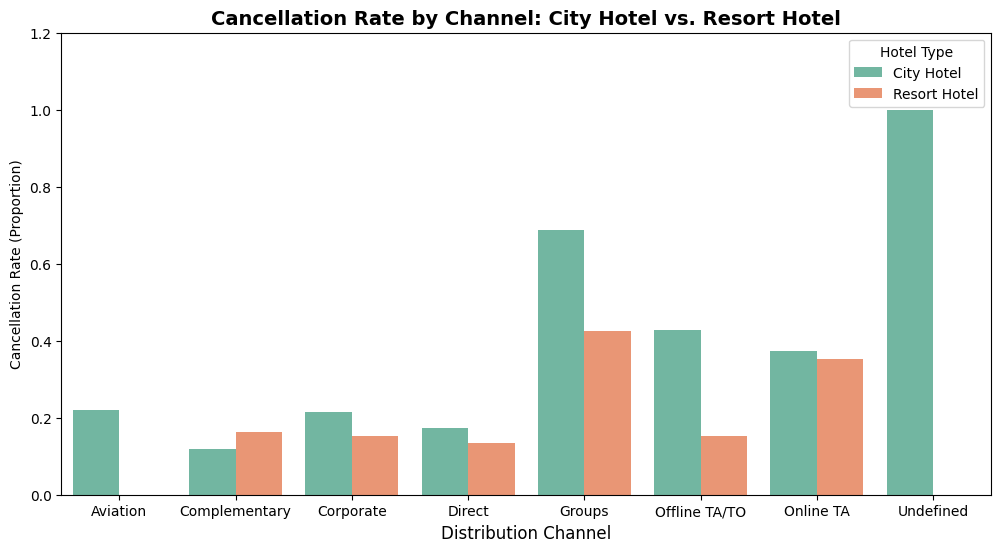

In [40]:
plt.figure(figsize=(10, 5))
sns.barplot(data=datos_grafica, x='market_segment', y='cancelada_num', palette='Blues_r', hue='market_segment', legend=False)
plt.title('Cancellation Rate by Commercial Channel', fontsize=14, fontweight='bold')
plt.xlabel('Distribution Channel', fontsize=12)
plt.ylabel('Cancellation Rate (Proportion)', fontsize=12)
plt.ylim(0, 1.15)
plt.show()

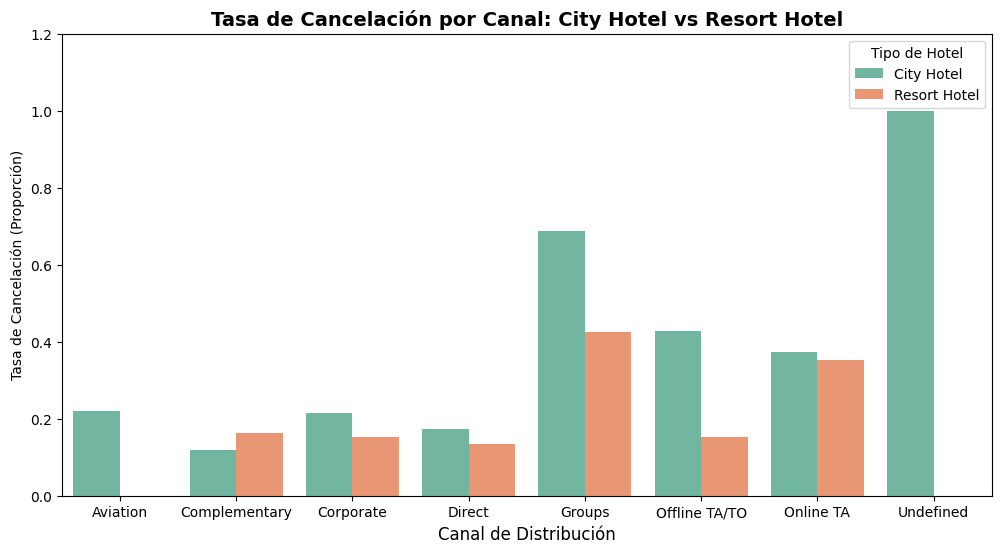

In [41]:
# Does channel cancellation risk impact City Hotel and Resort Hotel equally?

comparativa_tabla = df_real.groupby(['market_segment', 'hotel'])['cancelada_num'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=comparativa_tabla,
    x='market_segment',
    y='cancelada_num',
    hue='hotel',
    palette='Set2'
)
plt.title(
    'Cancellation Rate by Channel: City Hotel vs. Resort Hotel',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Distribution Channel', fontsize=12)
plt.ylabel('Cancellation Rate (Proportion)')
plt.ylim(0,1.2)
plt.legend(title='Hotel Type')
plt.show()

In [42]:
# Which months of the year achieve the highest realized Average Daily Rate (ADR)?

reservas_validas = df_real[df_real['is_canceled']=='No']

precio_mensual = reservas_validas.groupby('arrival_date_month')['adr'].mean().sort_values(ascending=False).reset_index()

precio_mensual['adr'] = precio_mensual['adr'].map('${:.2f}'.format)

precio_mensual

,arrival_date_month,adr
0,August,$142.09
1,July,$129.25
2,June,$114.59
3,September,$107.28
4,May,$104.84
5,April,$97.88
6,October,$86.83
7,December,$78.92
8,March,$77.34
9,February,$72.42


In [43]:
#Ya sabemos que Agosto es el mes más caro a nivel global ($142.09). Pero, ¿este aumento en verano se debe al Resort Hotel (playa/vacacional) o el City Hotel (negocios/urbano) también sube sus precios al mismo nivel?

adr_por_hotel = reservas_validas.groupby(['hotel', 'arrival_date_month'])['adr'].mean().sort_values(ascending=False).reset_index()

adr_por_hotel[adr_por_hotel['arrival_date_month'] == 'August']


,hotel,arrival_date_month,adr
0,Resort Hotel,August,181.205892
3,City Hotel,August,118.412083


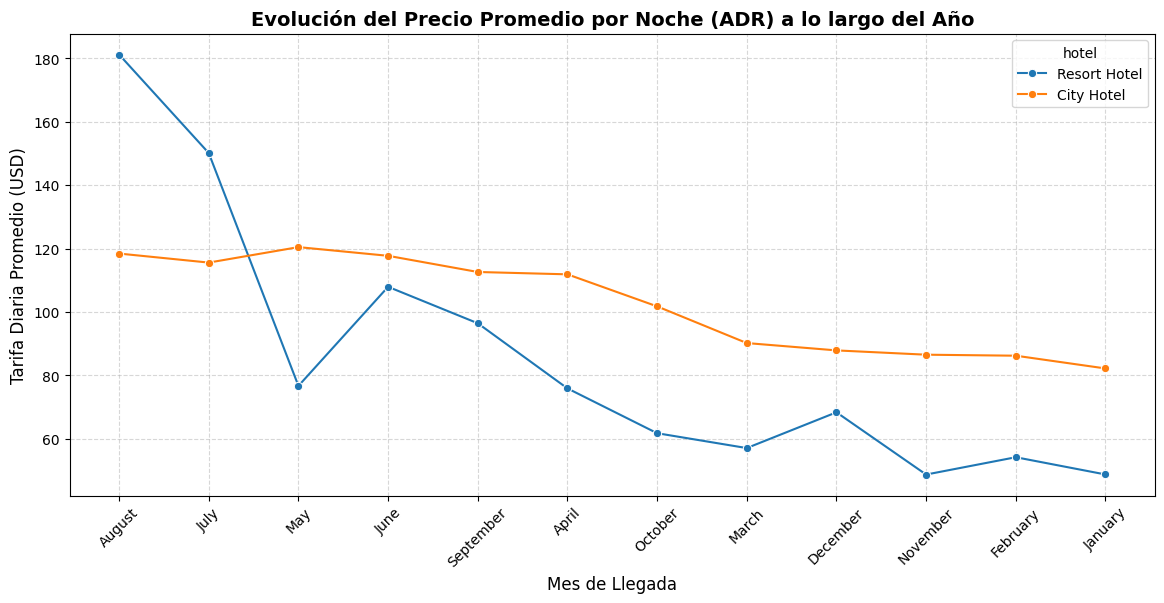

In [44]:
plt.figure(figsize=(14,6))
sns.lineplot(
    data=adr_por_hotel,
    x='arrival_date_month',
    y='adr',
    hue='hotel',
    marker='o'
)
plt.title(
    'Average Daily Rate (ADR) Seasonality Across the Year',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Arrival Month', fontsize=12)
plt.ylabel('Average Daily Rate (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [45]:
reservas_validas = df_real[df_real['is_canceled'] == 'No'].copy()

orden_meses = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December',
]

reservas_validas['arrival_date_month'] = pd.Categorical(reservas_validas['arrival_date_month'], categories=orden_meses, ordered=True)

adr_por_hotel = (reservas_validas.groupby(['hotel', 'arrival_date_month'], observed=True)['adr'].mean().reset_index())



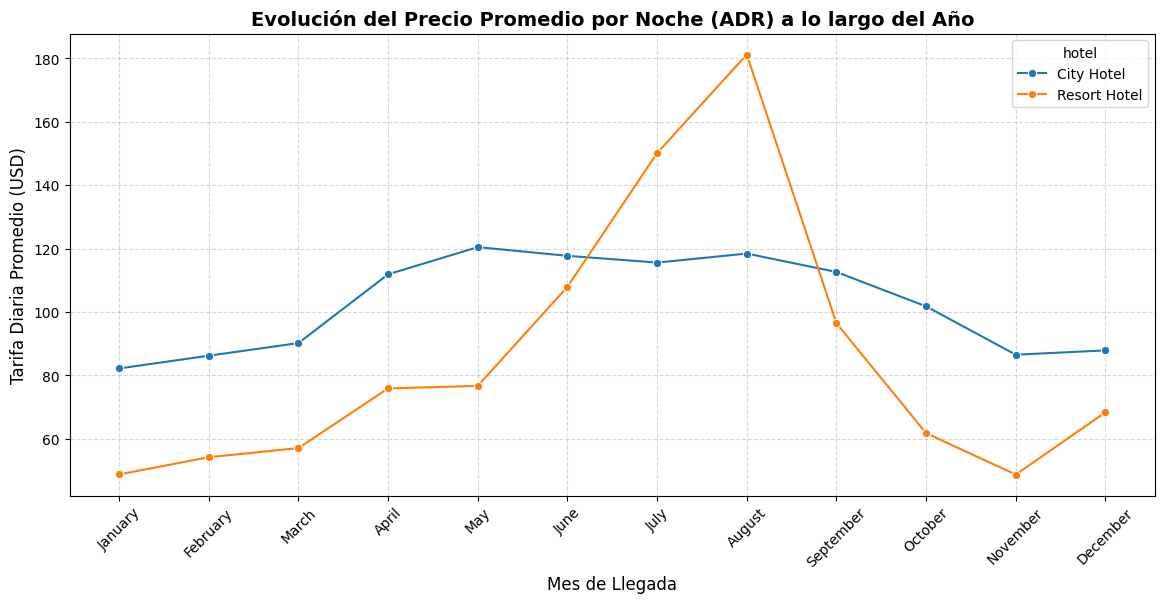

In [46]:
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=adr_por_hotel,
    x='arrival_date_month',
    y='adr',
    hue='hotel',
    marker='o',
)
plt.title(
    'Average Daily Rate (ADR) Seasonality Across the Year',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Arrival Month', fontsize=12)
plt.ylabel('Average Daily Rate (USD)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [47]:
# Is August also the month with the highest confirmed guest volume?

ocupacion_mensual = reservas_validas.groupby('arrival_date_month', observed=True)['hotel'].count().reset_index()

ocupacion_mensual.columns = ['Month', 'Total_Confirmed_Guests']

ocupacion_mensual

,Mes,Total_Huespedes
0,January,4122
1,February,5372
2,March,6644
3,April,6565
4,May,7114
5,June,6404
6,July,7919
7,August,8638
8,September,6392
9,October,6914


In [48]:
# What are the top 5 origin countries for confirmed hotel guests?

Top_Paises = reservas_validas['country'].value_counts().head().reset_index()

Top_Paises.columns = ['Country', 'Total_Bookings']

Top_Paises

,Pais,Total_Reservas
0,PRT,21071
1,GBR,9675
2,FRA,8481
3,ESP,6391
4,DEU,6069


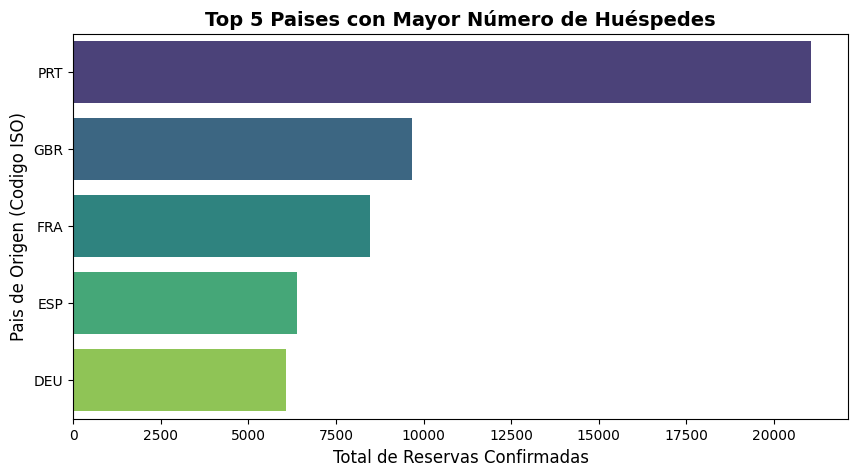

In [49]:
plt.figure(figsize=(10, 5))
sns.barplot(data=Top_Paises, x='Total_Bookings', y='Country', palette='viridis', hue='Country', legend=False)
plt.title('Top 5 Guest Origin Countries (Confirmed Bookings)', fontsize=14, fontweight='bold')
plt.xlabel('Total Confirmed Bookings', fontsize=12)
plt.ylabel('Origin Country (ISO Code)', fontsize=12)
plt.show()

In [50]:
# Which market segments generate the largest overall booking volume?

segmentos_mercado = df_real['market_segment'].value_counts().reset_index()

segmentos_mercado

,market_segment,count
0,Online TA,56477
1,Offline TA/TO,24218
2,Groups,19810
3,Direct,12606
4,Corporate,5295
5,Complementary,743
6,Aviation,237
7,Undefined,2


In [51]:
traduccion_inversa = {'Yes' : 1, 'No' : 0}
df_real['is_canceled'] = df_real['is_canceled'].map(traduccion_inversa)

In [52]:
# What is the cancellation rate across each market segment?

cancelacion_por_segmento = df_real.groupby('market_segment')['is_canceled'].mean().sort_values(ascending=False).map('{:.2%}'.format).reset_index()

cancelacion_por_segmento

,market_segment,is_canceled
0,Undefined,100.00%
1,Groups,61.07%
2,Online TA,36.72%
3,Offline TA/TO,34.31%
4,Aviation,21.94%
5,Corporate,18.73%
6,Direct,15.34%
7,Complementary,13.06%


In [53]:
# Among confirmed stays, which market segment pays the highest and lowest average daily rate (ADR)?

adr_por_segmento = reservas_validas.groupby('market_segment')['adr'].mean().sort_values(ascending=False).map('${:.2f}'.format).reset_index()

adr_por_segmento

,market_segment,adr
0,Direct,$113.88
1,Online TA,$113.86
2,Aviation,$99.48
3,Offline TA/TO,$83.42
4,Groups,$77.14
5,Corporate,$67.11
6,Complementary,$3.08


In [54]:
# What is the average booking lead time (in days) for each market segment?

anticipacion_por_segmento = df_real.groupby('market_segment')['lead_time'].mean().sort_values(ascending=False).round(2).reset_index()

anticipacion_por_segmento

,market_segment,lead_time
0,Groups,186.97
1,Offline TA/TO,135.01
2,Online TA,83.00
3,Direct,49.86
4,Corporate,22.13
5,Complementary,13.29
6,Aviation,4.44
7,Undefined,1.50


In [55]:
# Does a higher number of special requests correlate with lower cancellation probability?

peticiones_vs_cancelacion = df_real.groupby('total_of_special_requests')['is_canceled'].mean().sort_values(ascending=False).map("{:.2%}".format).reset_index()

peticiones_vs_cancelacion

,total_of_special_requests,is_canceled
0,0,47.72%
1,2,22.10%
2,1,22.02%
3,3,17.86%
4,4,10.59%
5,5,5.00%


In [56]:
# Which customer profile exhibits the highest cancellation rate?

cancelacion_por_tipo_de_cliente = df_real.groupby('customer_type')['is_canceled'].mean().sort_values(ascending=False).map("{:.2%}".format).reset_index()

cancelacion_por_tipo_de_cliente

,customer_type,is_canceled
0,Transient,40.75%
1,Contract,30.96%
2,Transient-Party,25.43%
3,Group,10.23%


In [57]:
# How does parking space allocation impact booking cancellation rates?

cancelacion_por_parking = df_real.groupby('required_car_parking_spaces')['is_canceled'].mean().map("{:.2%}".format).reset_index()

cancelacion_por_parking

,required_car_parking_spaces,is_canceled
0,0,39.49%
1,1,0.00%
2,2,0.00%
3,3,0.00%
4,8,0.00%


In [58]:
# What proportion of total bookings corresponds to repeated guests vs. first-time guests?

proporcion_clientes = df_real['is_repeated_guest'].value_counts(normalize=True).map('{:.2%}'.format)

proporcion_clientes.index = proporcion_clientes.index.map({0: 'First-Time', 1: 'Repeated'})

proporcion_clientes

,proportion
is_repeated_guest,
First-Time,96.81%
Repeated,3.19%


In [59]:
cancelacion_fidelidad = df_real.groupby('is_repeated_guest')['is_canceled'].mean().map('{:.2%}'.format).reset_index()

cancelacion_fidelidad['is_repeated_guest'] = cancelacion_fidelidad['is_repeated_guest'].map({0: 'First-Time', 1: 'Repeated'})

cancelacion_fidelidad

,is_repeated_guest,is_canceled
0,First-Time,37.78%
1,Repeated,14.49%


In [60]:
cancelacion_por_deposito = df_real.groupby('deposit_type')['is_canceled'].mean().sort_values(ascending=False).map('{:.2%}'.format).reset_index()

cancelacion_por_deposito

,deposit_type,is_canceled
0,Non Refund,99.36%
1,No Deposit,28.38%
2,Refundable,22.22%


In [61]:
cruces_deposito = pd.crosstab(df_real['market_segment'], df_real['deposit_type'])

cruces_deposito

deposit_type,No Deposit,Non Refund,Refundable
market_segment,,,
Aviation,237,0,0
Complementary,743,0,0
Corporate,4957,334,4
Direct,12581,19,6
Groups,10508,9172,130
Offline TA/TO,19209,5005,4
Online TA,56403,56,18
Undefined,2,0,0


In [62]:
# Which months register the highest and lowest volume of confirmed arrivals?

demanda_mensual = reservas_validas['arrival_date_month'].value_counts().reset_index()

demanda_mensual

,arrival_date_month,count
0,August,8638
1,July,7919
2,May,7114
3,October,6914
4,March,6644
5,April,6565
6,June,6404
7,September,6392
8,February,5372
9,November,4672


In [63]:
# What is the average completed stay duration (nights) in City Hotel vs. Resort Hotel?

reservas_validas['total_estancia'] = reservas_validas['stays_in_weekend_nights'] + reservas_validas['stays_in_week_nights']

estancia_promedio = reservas_validas.groupby('hotel')['total_estancia'].mean().round(2).reset_index()

estancia_promedio


,hotel,total_estancia
0,City Hotel,2.92
1,Resort Hotel,4.14


In [64]:
import duckdb

In [65]:
# SQL query: Extract the first 5 booking records displaying hotel, market_segment, and adr

consulta_sql = duckdb.sql("""
SELECT hotel, market_segment, adr
FROM df_real
LIMIT 5
""").df()

consulta_sql

,hotel,market_segment,adr
0,Resort Hotel,Direct,0.0
1,Resort Hotel,Direct,0.0
2,Resort Hotel,Direct,75.0
3,Resort Hotel,Corporate,75.0
4,Resort Hotel,Online TA,98.0


In [66]:
# SQL query: Top 10 confirmed bookings ordered by highest ADR

consulta_filtro = duckdb.sql("""
SELECT hotel, lead_time, adr
FROM df_real
WHERE is_canceled = 0
ORDER BY adr DESC
LIMIT 10
""").df()

consulta_filtro

,hotel,lead_time,adr
0,City Hotel,0,510.00
1,Resort Hotel,1,508.00
2,City Hotel,81,451.50
3,Resort Hotel,31,426.25
4,Resort Hotel,104,402.00
5,Resort Hotel,26,397.38
6,Resort Hotel,24,392.00
7,Resort Hotel,64,388.00
8,Resort Hotel,40,387.00
9,Resort Hotel,178,383.00


In [67]:
# SQL query: First 5 confirmed bookings from the Online TA segment

consulta_texto = duckdb.sql("""
SELECT hotel, market_segment, adr
FROM df_real
WHERE is_canceled = 0 AND market_segment = 'Online TA'
LIMIT 5
""").df()

consulta_texto

,hotel,market_segment,adr
0,Resort Hotel,Online TA,98.00
1,Resort Hotel,Online TA,98.00
2,Resort Hotel,Online TA,145.00
3,Resort Hotel,Online TA,97.00
4,Resort Hotel,Online TA,154.77


In [68]:
# SQL query: Average Daily Rate (ADR) by hotel type ordered descending

consulta_agrupada = duckdb.sql("""
SELECT hotel, AVG(adr) AS tarifa_promedio
FROM df_real
GROUP BY hotel
ORDER BY tarifa_promedio DESC
""").df()

consulta_agrupada

,hotel,tarifa_promedio
0,City Hotel,105.237722
1,Resort Hotel,94.955459


In [69]:
# SQL query: Total bookings and average ADR for major distribution channels (> 5,000 bookings)

consulta_segmentos = duckdb.sql("""
SELECT market_segment, COUNT(*) AS total_reservas, ROUND(AVG(adr),2) AS tarifa_promedio
FROM df_real
GROUP BY market_segment
HAVING COUNT(*) > 5000
ORDER BY total_reservas DESC
""").df()

consulta_segmentos

,market_segment,total_reservas,tarifa_promedio
0,Online TA,56477,117.20
1,Offline TA/TO,24218,87.14
2,Groups,19810,79.48
3,Direct,12606,115.45
4,Corporate,5295,69.36


In [70]:
# SQL query: Consolidated KPIs per property (total bookings, total cancelled, average ADR)

consulta_hotel_kpis = duckdb.sql("""
SELECT hotel, COUNT(*) AS total_reservas, SUM(is_canceled) AS total_canceladas, ROUND(AVG(adr), 2) AS tarifa_promedio
FROM df_real
GROUP BY hotel
""").df()

consulta_hotel_kpis

,hotel,total_reservas,total_canceladas,tarifa_promedio
0,City Hotel,79329,33101.0,105.24
1,Resort Hotel,40059,11122.0,94.96


In [71]:
# SQL query: Annual confirmed bookings, total adults hosted, and average ADR by arrival year

consulta_anual = duckdb.sql("""
    SELECT arrival_date_year, COUNT(*) AS reservas_efectivas, SUM(adults) AS total_adultos, ROUND(AVG(adr), 2) AS tarifa_promedio
    FROM df_real
    WHERE is_canceled = 0
    GROUP BY arrival_date_year
    ORDER BY arrival_date_year DESC
""").df()

consulta_anual

,arrival_date_year,reservas_efectivas,total_adultos,tarifa_promedio
0,2017,24941,46035.0,111.32
1,2016,36370,66771.0,96.52
2,2015,13854,24726.0,88.71


In [72]:
# SQL query: Average confirmed ADR per property in 2017

consulta_hotel_anual = duckdb.sql("""
SELECT hotel, ROUND(AVG(adr), 2) AS tarifa_promedio
FROM df_real
WHERE is_canceled = 0 AND arrival_date_year = 2017
GROUP BY hotel
ORDER BY hotel ASC
""").df()

consulta_hotel_anual

,hotel,tarifa_promedio
0,City Hotel,116.82
1,Resort Hotel,101.78


In [73]:
# SQL query: Segment confirmed bookings by lead time ('Last Minute', 'Early Bird', 'Long Term')

consulta_anticipacion = duckdb.sql("""
SELECT
  CASE
  WHEN lead_time < 7 THEN 'Last Minute'
  WHEN lead_time <= 30 THEN 'Early Bird'
  ELSE 'Long Term'
  END AS tipo_anticipacion,
  COUNT (*) AS total_reservas,
  ROUND(AVG(adr), 2) AS tarifa_promedio
FROM df_real
WHERE is_canceled = 0
GROUP BY tipo_anticipacion
ORDER BY total_reservas DESC
""").df()

consulta_anticipacion

,tipo_anticipacion,total_reservas,tarifa_promedio
0,Long Term,43644,102.94
1,Última Hora,16685,89.00
2,Early Bird,14836,103.66


In [74]:
# SQL query: Confirmed bookings and average ADR for direct and niche channels (excluding OTA/Groups)

consulta_canales_directos = duckdb.sql("""
SELECT
  market_segment,
  COUNT(*) AS total_reservas,
  ROUND(AVG(adr), 2) AS tarifa_promedio
FROM df_real
WHERE is_canceled = 0 AND market_segment NOT IN ('Online TA', 'Offline TA/TO', 'Groups')
GROUP BY market_segment
ORDER BY total_reservas DESC
""").df()

consulta_canales_directos

,market_segment,total_reservas,tarifa_promedio
0,Direct,10672,113.88
1,Corporate,4303,67.11
2,Complementary,646,3.08
3,Aviation,185,99.48


In [75]:
# SQL query: Representative commercial channels with over 1,000 confirmed bookings

consulta_canales_principales = duckdb.sql("""
SELECT
  market_segment,
  COUNT(*) AS total_reservas,
  ROUND(AVG(adr), 2) AS tarifa_promedio
FROM df_real
WHERE is_canceled = 0
GROUP BY market_segment
HAVING COUNT(*) > 1000
ORDER BY total_reservas DESC
""").df()

consulta_canales_principales

,market_segment,total_reservas,tarifa_promedio
0,Online TA,35738,113.86
1,Offline TA/TO,15908,83.42
2,Direct,10672,113.88
3,Groups,7713,77.14
4,Corporate,4303,67.11


In [76]:
consulta_cte_hoteles = duckdb.sql("""
WITH resumen_hoteles AS (
  SELECT
    hotel,
    COUNT(*) AS total_reservas,
    ROUND(AVG(adr), 2) AS tarifa_promedio
  FROM df_real
  WHERE is_canceled = 0
  GROUP BY hotel
)
SELECT
  hotel,
  total_reservas,
  tarifa_promedio
FROM resumen_hoteles
WHERE total_reservas > 25000
ORDER BY total_reservas DESC
""").df()

consulta_cte_hoteles

,hotel,total_reservas,tarifa_promedio
0,City Hotel,46228,105.75
1,Resort Hotel,28937,90.79


In [77]:
consulta_metricas_cte = duckdb.sql("""
WITH hoteles_confirmados AS (
  SELECT
    hotel,
    COUNT(*) AS total_confirmadas,
    ROUND(AVG(lead_time), 2) AS anticipacion_promedio
  FROM df_real
  WHERE is_canceled = 0
  GROUP BY hotel
)
SELECT
  hotel,
  total_confirmadas,
  anticipacion_promedio
FROM hoteles_confirmados
WHERE total_confirmadas > 20000
ORDER BY total_confirmadas DESC
""").df()

consulta_metricas_cte

,hotel,total_confirmadas,anticipacion_promedio
0,City Hotel,46228,80.70
1,Resort Hotel,28937,78.83


In [78]:
consulta_noches_hotel = duckdb.sql("""
  SELECT
  hotel,
  COUNT(*) AS total_reservas,
  SUM(stays_in_weekend_nights) AS total_noches_fin_de_semana,
  SUM (stays_in_week_nights) AS total_noches_semana
  FROM df_real
  WHERE is_canceled = 0
  GROUP BY hotel
  ORDER BY total_reservas DESC
""").df()

consulta_noches_hotel

,hotel,total_reservas,total_noches_fin_de_semana,total_noches_semana
0,City Hotel,46228,37014.0,98139.0
1,Resort Hotel,28937,32809.0,87068.0


In [79]:
# SQL query: Total realized lodging revenue generated by each property

consulta_ingresos_hotel = duckdb.sql("""
SELECT
    hotel,
    PRINTF('%,f', COUNT(*)) AS total_reservas,
    PRINTF('$%,.2f', SUM(adr * (stays_in_weekend_nights + stays_in_week_nights)), 2) AS ingresos_totales
FROM df_real
WHERE is_canceled = 0
GROUP BY hotel
ORDER BY ingresos_totales DESC
""").df()

consulta_ingresos_hotel

,hotel,total_reservas,ingresos_totales
0,City Hotel,"46,228","$14,394,410.18"
1,Resort Hotel,"28,937","$11,601,914.03"


In [80]:
# SQL query: Average realized revenue per confirmed booking (Average Ticket) by hotel

consulta_ticket_promedio = duckdb.sql("""
SELECT
  hotel,
  PRINTF('%,f', COUNT(*)) AS total_reservas,
  PRINTF('$%,.2f', SUM(adr * (stays_in_week_nights + stays_in_weekend_nights))) AS ingresos_totales,
  PRINTF('$%,.2f', SUM(adr * (stays_in_week_nights + stays_in_weekend_nights)) / COUNT (*)) AS ticket_promedio_por_reserva
FROM df_real
WHERE is_canceled = 0
GROUP BY hotel
ORDER BY ingresos_totales DESC
""").df()

consulta_ticket_promedio

,hotel,total_reservas,ingresos_totales,ticket_promedio_por_reserva
0,City Hotel,"46,228","$14,394,410.18",$311.38
1,Resort Hotel,"28,937","$11,601,914.03",$400.94


In [81]:
df_catalogo_meal = pd.DataFrame({
    'codigo_meal': ['BB', 'HB', 'FB', 'SC', 'Undefined'],
    'descripcion_plan': ['Bed & Breakfast', 'Half Board', 'Full Board', 'Self Catering', 'Undefined']
})

consulta_planes_comida = duckdb.sql("""
SELECT
  cat.descripcion_plan,
  COUNT(*) AS total_reservas
FROM df_real AS r
INNER JOIN df_catalogo_meal AS cat
  ON r.meal = cat.codigo_meal
WHERE r.is_canceled = 0
GROUP BY cat.descripcion_plan
ORDER BY total_reservas DESC
""").df()

consulta_planes_comida



,descripcion_plan,total_reservas
0,Bed & Breakfast,57799
1,Half Board (Media Pensión),9479
2,Self Catering,6684
3,Undefined,883
4,Full Board (Pensión Completa),320


In [82]:
# SQL query: Total realized lodging revenue broken down by meal plan package

consulta_ingresos_plan = duckdb.sql("""
SELECT
  cat.descripcion_plan,
  PRINTF('%,d', COUNT(*)) AS total_reservas,
  PRINTF('$%,.2f', SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights))) AS ingresos_totales
FROM df_real AS r
INNER JOIN df_catalogo_meal AS cat
  ON r.meal = cat.codigo_meal
WHERE r.is_canceled = 0
GROUP BY cat.descripcion_plan
ORDER BY SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights)) DESC
""").df()

consulta_ingresos_plan

,descripcion_plan,total_reservas,ingresos_totales
0,Bed & Breakfast,"57,799","$18,671,044.54"
1,Half Board (Media Pensión),"9,479","$5,034,459.67"
2,Self Catering,"6,684","$1,677,654.02"
3,Undefined,883,"$381,490.80"
4,Full Board (Pensión Completa),320,"$231,675.18"


In [83]:
# Data integrity audit: Detect unmapped or orphan meal plan codes against master catalog

consulta_auditoria_comidas = duckdb.sql("""
SELECT
  r.meal AS codigo_en_reserva,
  PRINTF('%,d', COUNT(*)) AS cantidad_reservas
FROM df_real AS r
LEFT JOIN df_catalogo_meal AS cat
  ON r.meal = cat.codigo_meal
WHERE cat.codigo_meal IS NULL
GROUP BY r.meal
""").df()

consulta_auditoria_comidas

,codigo_en_reserva,cantidad_reservas


In [84]:
df_catalogo_incompleto = pd.DataFrame({
    'codigo_meal': ['BB', 'HB', 'FB'],
    'descripcion_plan': ['Bed & Breakfast', 'Half Board', 'Full Board']
})

consulta_prueba_discrepancias = duckdb.sql("""
SELECT
  r.meal AS codigo_huerfano,
  PRINTF('%,d', COUNT(*)) AS total_reservas_afectadas
FROM df_real AS r
LEFT JOIN df_catalogo_incompleto AS cat
  ON r.meal = cat.codigo_meal
WHERE cat.codigo_meal IS NULL
GROUP BY r.meal
ORDER BY COUNT(*) DESC
""").df()

consulta_prueba_discrepancias

,codigo_huerfano,total_reservas_afectadas
0,SC,"10,650"
1,Undefined,"1,169"


In [85]:
def auditar_catalogo_comidas (tabla_reservas, tabla_catalogo):
  reporte_huerfanos = duckdb.sql("""
    SELECT
      r.meal AS codigo_huerfano,
      PRINTF('%,d', COUNT (*)) AS total_afectadas
    FROM tabla_reservas AS r
    LEFT JOIN tabla_catalogo AS cat
      ON r.meal = cat.codigo_meal
    WHERE cat.codigo_meal IS NULL
    GROUP BY r.meal
    ORDER BY COUNT (*) DESC
  """).df()

  if len(reporte_huerfanos) == 0:
    print("Audit Passed: 100% Referential Integrity. All codes are registered.")
    return None
  else:
    print(f"Operational Alert: Detected {len(reporte_huerfanos)} orphan codes.")
    return reporte_huerfanos

auditar_catalogo_comidas(df_real, df_catalogo_meal)

print("-" * 60)

auditar_catalogo_comidas(df_real, df_catalogo_incompleto)

Auditoría Exitosa: Integridad al 100%. Todos los códigos están registrados.
------------------------------------------------------------
Alerta Operativa: Se detectaron 2 códigos huérfanos.


,codigo_huerfano,total_afectadas
0,SC,"10,650"
1,Undefined,"1,169"


In [86]:
df_catalogo_deposit = pd.DataFrame({
    'tipo_oficial': ['No Deposit', 'Non Refund', 'Refundable']
})

def auditar_depositos (tabla_reservas, tabla_depositos):
  reporte_depositos = duckdb.sql("""
  SELECT
    r.deposit_type AS codigo_depositos,
    PRINTF('%,d', COUNT(*)) AS total_reservas
  FROM tabla_reservas AS r
  LEFT JOIN tabla_depositos AS cat
    ON r.deposit_type = cat.tipo_oficial
  WHERE cat.tipo_oficial IS NULL
  GROUP BY r.deposit_type
  ORDER BY COUNT(*) DESC
  """).df()

  if len (reporte_depositos) == 0:
    print("Audit Passed: 100% Referential Integrity. All codes are registered.")
    return None
  else:
    print (f"Operational Alert: Detected {len(reporte_depositos)} orphan codes.")
    return reporte_depositos

auditar_depositos(df_real, df_catalogo_deposit)

print ("-" * 60)

Auditoría Exitosa: Integridad al 100%. Todos los códigos están registrados.
------------------------------------------------------------


In [87]:
# Null audit scan across all columns in df_real

nulos_por_columna = df_real.isnull().sum()

nulos_por_columna[nulos_por_columna > 0]

,0


In [88]:
df_real.isna().sum().sum()

np.int64(0)

In [89]:
consulta_coalesce = duckdb.sql("""
SELECT
  r.meal AS codigo_original,
  COALESCE(cat.descripcion_plan, 'Unregistered Code') AS plan_limpio,
  PRINTF('%,d', COUNT(*)) AS total_reservas
FROM df_real AS r
LEFT JOIN df_catalogo_incompleto AS cat
  ON r.meal = cat.codigo_meal
GROUP BY r.meal, cat.descripcion_plan
ORDER BY COUNT(*) DESC
""").df()

consulta_coalesce


,codigo_original,plan_limpio,total_reservas
0,BB,Bed & Breakfast,"92,308"
1,HB,Half Board,"14,463"
2,SC,Código No Registrado,"10,650"
3,Undefined,Código No Registrado,"1,169"
4,FB,Full Board,798


In [90]:
# Multidimensional revenue report crossing property type and meal plan package

reporte_maestro_hoteles = duckdb.sql("""
SELECT
  r.hotel,
  cat.descripcion_plan,
  PRINTF('%,d', COUNT(*)) AS reservas_confirmadas,
  PRINTF('$%,.2f', SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights))) AS ingresos_totales
FROM df_real AS r
INNER JOIN df_catalogo_meal AS cat
  ON r.meal = cat.codigo_meal
WHERE r.is_canceled = 0
GROUP BY r.hotel, cat.descripcion_plan
ORDER BY r.hotel ASC, SUM(r.adr * (r.stays_in_week_nights + r.stays_in_weekend_nights)) DESC
""").df()

reporte_maestro_hoteles

,hotel,descripcion_plan,reservas_confirmadas,ingresos_totales
0,City Hotel,Bed & Breakfast,"35,638","$11,334,961.83"
1,City Hotel,Self Catering,"6,601","$1,675,424.09"
2,City Hotel,Half Board (Media Pensión),"3,980","$1,383,602.76"
3,City Hotel,Full Board (Pensión Completa),9,$421.50
4,Resort Hotel,Bed & Breakfast,"22,161","$7,336,082.71"
5,Resort Hotel,Half Board (Media Pensión),"5,499","$3,650,856.91"
6,Resort Hotel,Undefined,883,"$381,490.80"
7,Resort Hotel,Full Board (Pensión Completa),311,"$231,253.68"
8,Resort Hotel,Self Catering,83,"$2,229.93"


In [97]:
reporte_maestro_hoteles['ingresos_totales'] = (
    reporte_maestro_hoteles['ingresos_totales']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [98]:
reporte_maestro_hoteles['ingresos_totales'].dtype

dtype('float64')

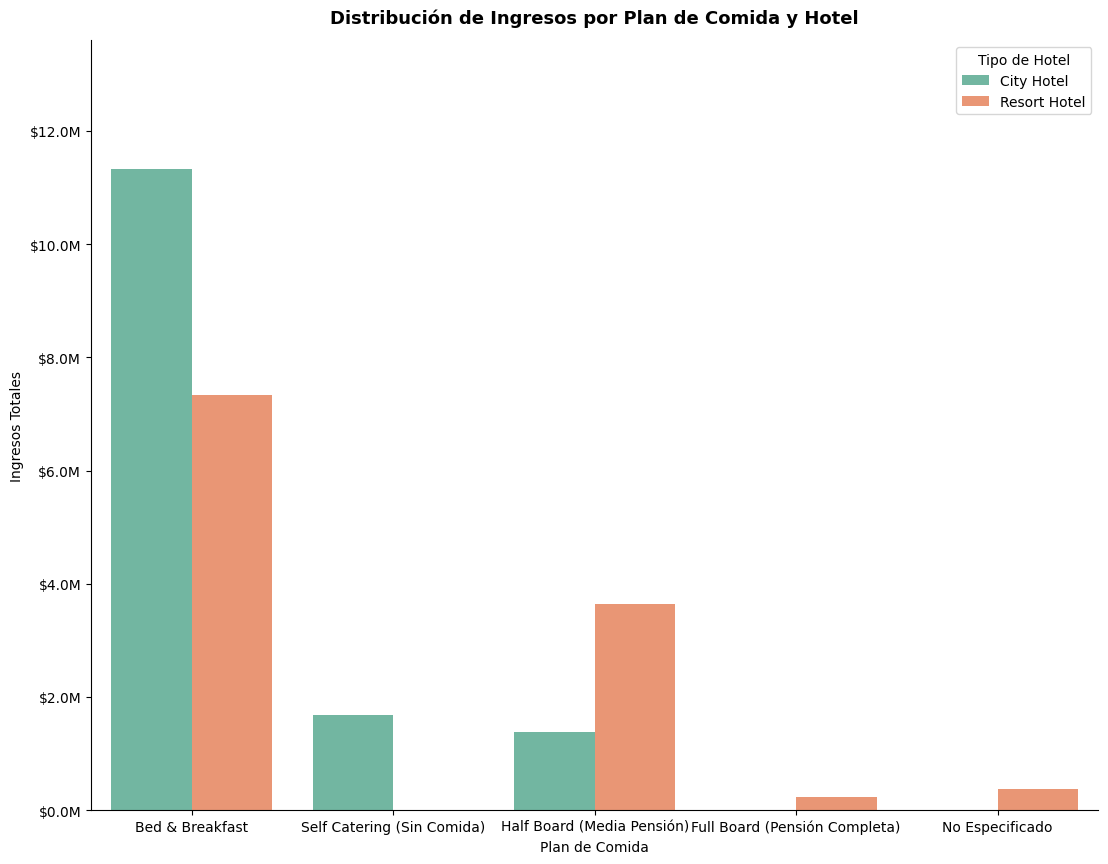

In [107]:
techo = reporte_maestro_hoteles['ingresos_totales'].max() * 1.2

import matplotlib.ticker as ticker

plt.figure(figsize=(13, 10))

ax= sns.barplot(
    data=reporte_maestro_hoteles,
    x= 'descripcion_plan',
    y= 'ingresos_totales',
    hue= 'hotel',
    palette= 'Set2'
    )
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x / 1_000_000:.1f}M'))

plt.title('Realized Revenue Distribution by Meal Plan and Hotel Type',
          fontsize=13,
          pad=12,
          fontweight='bold'
          )
plt.xlabel('Meal Plan', fontsize=10)
plt.ylabel('Total Realized Revenue (USD)', fontsize=10)
plt.ylim(0, techo)
plt.legend(title='Hotel Type')
sns.despine()

plt.show()